## TASK 07 - Penguins DataSet
> + Name : Anvesh Hirve
> + Batch no : 550
> + Module : EDA - Exploratory Data Analysis

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

### 1. Dataset Import and Preprocessing


In [10]:
penguins = sns.load_dataset('penguins')

In [11]:
penguins

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


### 2. Perform preprocessing tasks, including:

In [12]:
# Handling missing values
penguins.isnull().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

In [13]:
penguins['bill_length_mm'] = penguins['bill_length_mm'].fillna(penguins['bill_length_mm'].mean())
penguins['bill_depth_mm'] = penguins['bill_depth_mm'].fillna(penguins['bill_depth_mm'].mean())
penguins['flipper_length_mm'] = penguins['flipper_length_mm'].fillna(penguins['flipper_length_mm'].mean())
penguins['body_mass_g'] = penguins['body_mass_g'].fillna(penguins['body_mass_g'].mean())
penguins['sex'] = penguins['sex'].fillna(penguins['sex'].mode()[0])

In [14]:
penguins.isnull().sum()

species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

In [17]:
# Identifying and addressing outliers.

num_cols = penguins.select_dtypes(include='number').columns

Q1 = penguins[num_cols].quantile(0.25)
Q3 = penguins[num_cols].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier = (
    (penguins[num_cols] < lower) |
    (penguins[num_cols] > upper)
).any(axis=1)

print(outlier)

0      False
1      False
2      False
3      False
4      False
       ...  
339    False
340    False
341    False
342    False
343    False
Length: 344, dtype: bool


#### Conclusion
> + No outliers were detected in the numerical columns using the IQR method, so no outlier removal is required.

### 3. Data Visualization

#### Perform Univariate plots to analyze the dataset. (Both categorical and Numerical)

#### `A. Numerical columns`

<Axes: xlabel='bill_length_mm', ylabel='Count'>

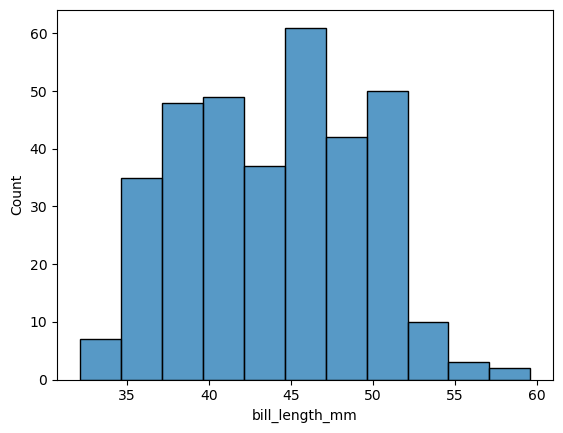

In [18]:
sns.histplot(penguins['bill_length_mm'])

**Observations**

1. Bill Length Histogram

> + The bill_length_mm values are mainly concentrated around the middle range.
> + The distribution shows some variation in bill lengths among penguins.

<Axes: xlabel='bill_depth_mm', ylabel='Count'>

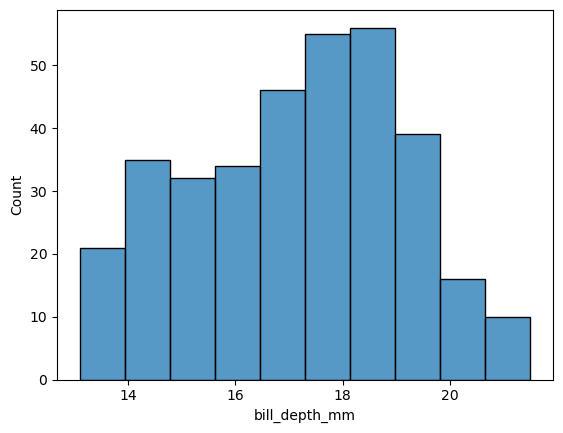

In [19]:
sns.histplot(penguins['bill_depth_mm'])

**Observation** 

2. Bill Depth Histogram

> + The bill_depth_mm values are concentrated around the central range.
> + The distribution shows variation in bill depth across the penguins.

<Axes: xlabel='flipper_length_mm', ylabel='Count'>

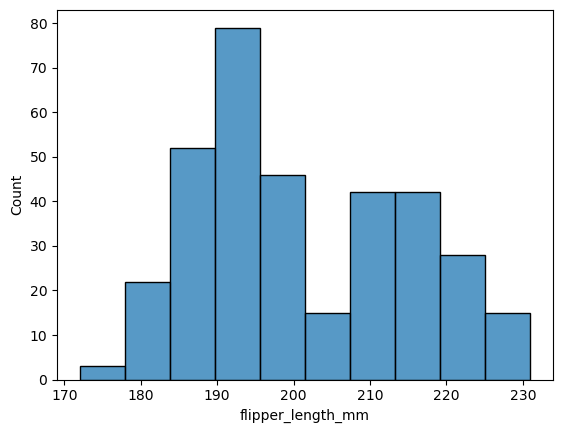

In [20]:
sns.histplot(penguins['flipper_length_mm'])

**Observation** 

3. Filpper Length Histogram

> + The flipper_length_mm values are concentrated around the central range.
> + The distribution shows variation in flipper_length_mm across the penguins.

<Axes: xlabel='body_mass_g', ylabel='Count'>

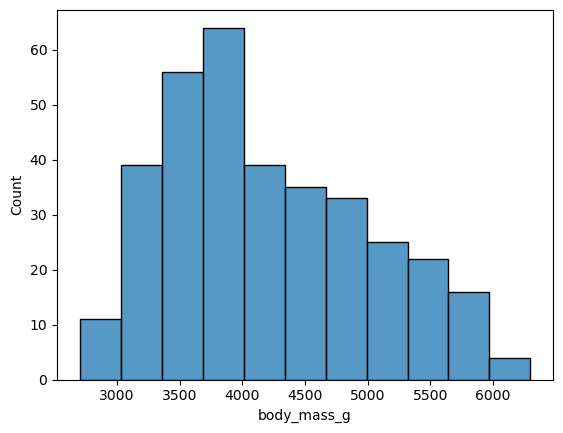

In [21]:
sns.histplot(penguins['body_mass_g'])

**Observation** 

4. Body Mass Histogram

> + The body_mass_g values are concentrated around the central range.
> + The distribution shows variation in body_mass_g across the penguins.

#### `B. Categorical columns`

<Axes: xlabel='count', ylabel='species'>

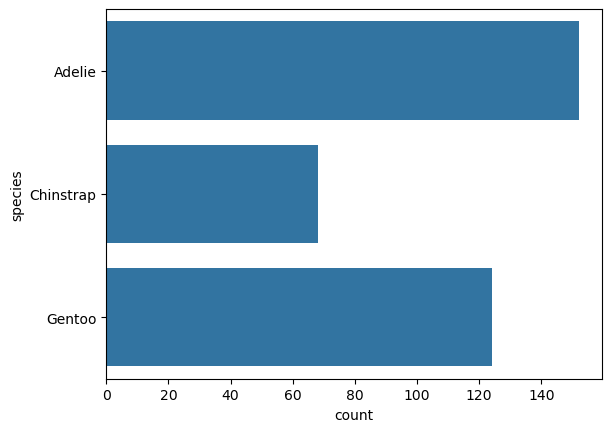

In [22]:
sns.countplot(penguins['species'])

**Observation** 

5. Species Count plot

> + The dataset contains three penguin species: Adelie, Chinstrap, and Gentoo.
> + Adelie has the highest number of observations.
> + Chinstrap has the lowest number of observations.

<Axes: xlabel='count', ylabel='island'>

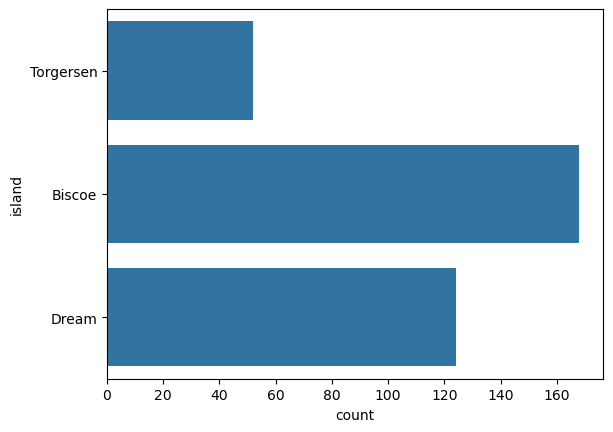

In [23]:
sns.countplot(penguins['island'])

**Observation** 

6. Island Count plot

> + Penguins are found on three islands: Biscoe, Dream, and Torgersen.
> + Biscoe has the highest number of penguin observations.
> + Torgersen has the lowest number of observations.

<Axes: xlabel='count', ylabel='sex'>

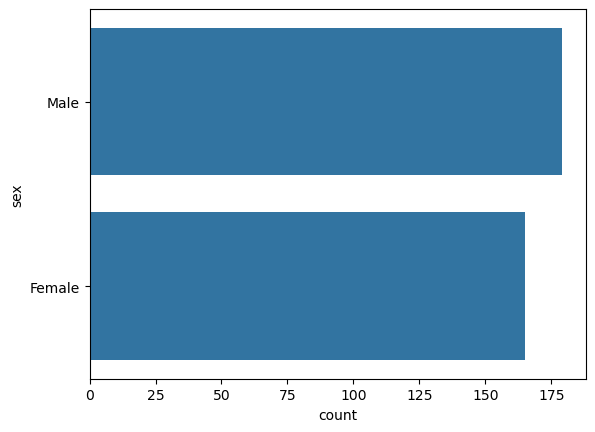

In [24]:
sns.countplot(penguins['sex'])

**Observation**

7. Gender Count Plot
> + Both male and female penguins are represented in the dataset.
> + The numbers of male and female penguins are relatively similar.
> + Missing sex values were handled during preprocessing. The original data had 11 missing values in sex.

#### Perform bivariate and multivariate plots to analyze the dataset. (Both categorical and Numerical)

### Bivariate Plots

<Axes: xlabel='bill_length_mm', ylabel='bill_depth_mm'>

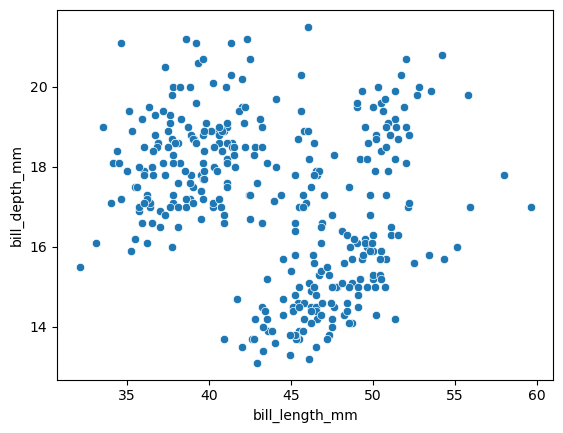

In [27]:
sns.scatterplot(data=penguins,x='bill_length_mm',y='bill_depth_mm')

**Observation**

8. Bill Length vs Bill Depth Scatter Plot
> + There is variation in bill length and bill depth among the penguins.
> + Different penguin species tend to occupy different regions of the plot.
> + This indicates that bill measurements can help distinguish between species.

<Axes: xlabel='species', ylabel='body_mass_g'>

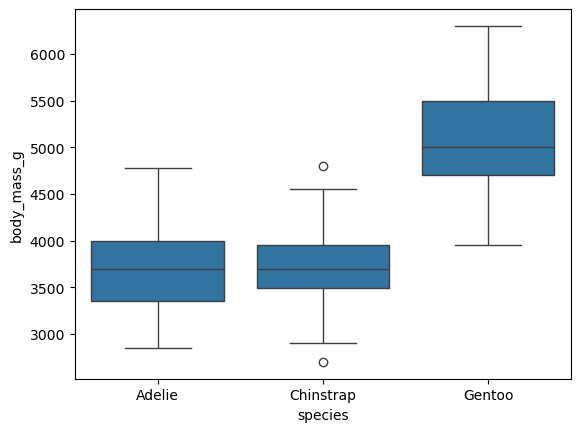

In [32]:
sns.boxplot(data=penguins,x='species',y='body_mass_g')

**Observation**

9. Body Mass by Species
> + Gentoo penguins generally have the highest body mass.
> + Adelie penguins generally have lower body mass than Gentoo.
> + Chinstrap penguins fall between the two groups in many cases.

<Axes: xlabel='species', ylabel='count'>

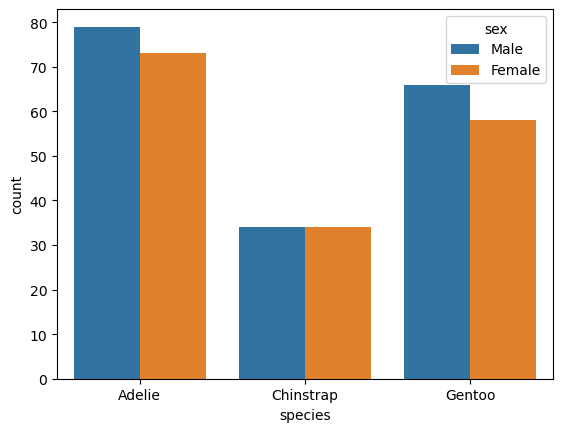

In [35]:
sns.countplot(data=penguins,x='species',hue='sex')

**Observation**

10.  Species by Gender
> + The count of Male Adelie penguins is higher than the count of Female Adelie penguins.
> + The counts of Male and Female Chinstrap penguins are equal.

### 3. Multivariate plots

<Axes: xlabel='bill_length_mm', ylabel='body_mass_g'>

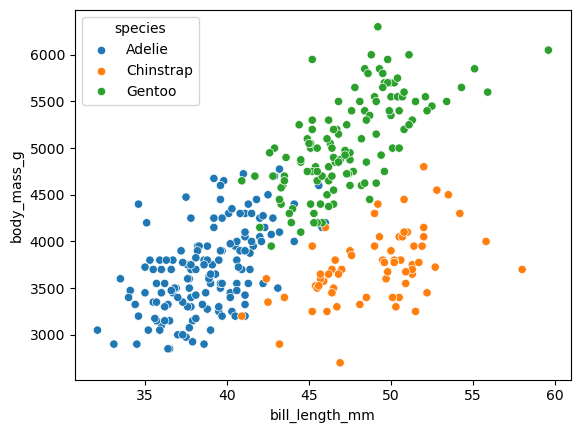

In [36]:
sns.scatterplot(data=penguins,x='bill_length_mm',y='body_mass_g',hue='species')

**Observation**

11.  Bill length vs Body Mass by species
> + There is variation and identification in bill length and body mass with the help of species among the penguins.
> + Different penguin species tend to occupy different regions of the plot.